# 01 - Exploratory data analysis and preparation

Dataset: `data/raw/loan_applications.csv`, **synthetic** historical vehicle-loan applications generated by
`data/generate_loans.py` (seeded, reproducible). It deliberately contains the defects found in real
loan books (missing values, data-entry outliers, inconsistent category spellings, duplicate submissions and
label noise from manual exceptions) so preparation can be demonstrated honestly.

Questions this notebook answers:
1. What does the data look like, and what is wrong with it?
2. Which applicant attributes separate approved from rejected loans?
3. How is the data cleaned, and what features are derived for modelling?

In [1]:
import sys, json, hashlib
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "backend"))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette=["#2b3ab0", "#f6607f", "#36c98b", "#ff9a3c", "#a46cf0"])
pd.set_option("display.width", 140, "display.max_columns", 30)
%matplotlib inline

In [2]:
raw = pd.read_csv(ROOT / "data/raw/loan_applications.csv", parse_dates=["application_date"])
print(raw.shape)
raw.head()

(12120, 15)


,application_id,application_date,monthly_income,credit_score,score_bureau,employment_category,employment_months,existing_emi,active_loans,requested_amount,tenure_months,down_payment,vehicle_type,region,loan_status
0,HIST-008124,2021-10-14,60200.0,754.0,CIBIL,Salaried,15.0,11200.0,2,1260000.0,48,52000.0,hatchback,IN-MH,Approved
1,HIST-004282,2022-08-23,104100.0,676.0,CIBIL,salaried,71.0,18400.0,2,2150000.0,84,303000.0,hatchback,IN-TN,Approved
2,HIST-008519,2025-02-12,75400.0,792.0,CIBIL,salaried,19.0,12400.0,2,1730000.0,72,783000.0,sedan,IN-MH,Approved
3,HIST-004771,2023-05-01,78000.0,664.0,CIBIL,salaried,101.0,0.0,0,2320000.0,72,673000.0,hatchback,IN-DL,Approved
4,HIST-005067,2021-04-14,46700.0,764.0,EQUIFAX,self_employed,40.0,0.0,0,410000.0,60,67000.0,suv,IN-DL,Approved


In [3]:
raw.dtypes.to_frame('dtype').T

,application_id,application_date,monthly_income,credit_score,score_bureau,employment_category,employment_months,existing_emi,active_loans,requested_amount,tenure_months,down_payment,vehicle_type,region,loan_status
dtype,str,datetime64[us],float64,float64,str,str,float64,float64,int64,float64,int64,float64,str,str,str


## 1. Data quality

In [4]:
quality = pd.DataFrame({"missing": raw.isna().sum(), "missing_%": (raw.isna().mean() * 100).round(2)})
quality[quality.missing > 0]

,missing,missing_%
credit_score,302,2.49
employment_months,385,3.18
down_payment,207,1.71


In [5]:
print("duplicate application ids:", raw.application_id.duplicated().sum())
print("exact duplicate rows:", raw.duplicated().sum())
raw.employment_category.value_counts(dropna=False)

duplicate application ids: 120
exact duplicate rows: 120


employment_category
salaried         7818
self_employed    2781
unemployed        404
retired           380
student           266
SALARIED          121
Salaried          113
salaried          110
Self-Employed      64
self employed      63
Name: count, dtype: int64

In [6]:
raw[["monthly_income", "existing_emi", "requested_amount", "down_payment", "credit_score",
     "employment_months", "active_loans", "tenure_months"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
monthly_income,12120.0,71012.7,128599.5,5320.0,37400.0,54700.0,79600.0,4100000.0
existing_emi,12120.0,7706.6,11005.4,0.0,0.0,4300.0,11000.0,228700.0
requested_amount,12120.0,1128107.3,862498.0,100000.0,520000.0,900000.0,1470000.0,6000000.0
down_payment,11913.0,280504.7,295180.9,0.0,81000.0,189000.0,374000.0,2978000.0
credit_score,11818.0,705.0,71.5,416.0,658.0,705.0,753.0,900.0
employment_months,11735.0,47.0,39.4,0.0,18.0,38.0,66.0,349.0
active_loans,12120.0,1.1,1.0,0.0,0.0,1.0,2.0,6.0
tenure_months,12120.0,56.3,15.7,24.0,48.0,60.0,60.0,84.0


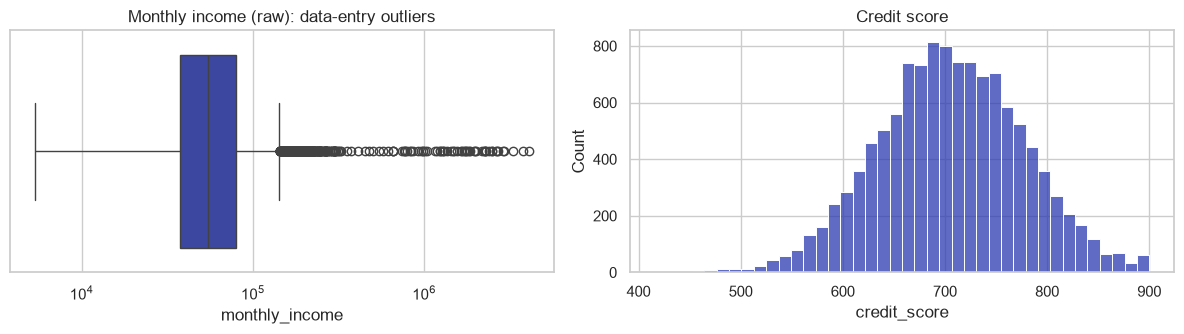

incomes above 10,00,000/month (treated as entry errors): 41


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=raw.monthly_income, ax=axes[0]).set(title="Monthly income (raw): data-entry outliers", xscale="log")
sns.histplot(raw.credit_score.dropna(), bins=40, ax=axes[1]).set(title="Credit score")
plt.tight_layout(); plt.show()
print("incomes above 10,00,000/month (treated as entry errors):", (raw.monthly_income > 1_000_000).sum())

**Findings.** Several numeric fields have missing values (bureau no-hit, optional fields left blank);
a small number of incomes are about 25 times too large (an extra digit or annual entered as monthly);
`employment_category` has several spellings of the same value; and some applications were submitted twice.

## 2. Target and relationships

In [8]:
print(raw.loan_status.value_counts(normalize=True).round(3))
df_view = raw.assign(approved=(raw.loan_status == "Approved").astype(int),
                     emi_to_income=raw.existing_emi / raw.monthly_income,
                     score_band=pd.cut(raw.credit_score, [299, 600, 650, 700, 750, 900]))
df_view.groupby("score_band", observed=True).approved.agg(["mean", "count"]).round(3)

loan_status
Approved    0.534
Rejected    0.466
Name: proportion, dtype: float64


,mean,count
score_band,,
"(299, 600]",0.021,858
"(600, 650]",0.026,1764
"(650, 700]",0.632,3007
"(700, 750]",0.669,3057
"(750, 900]",0.736,3132


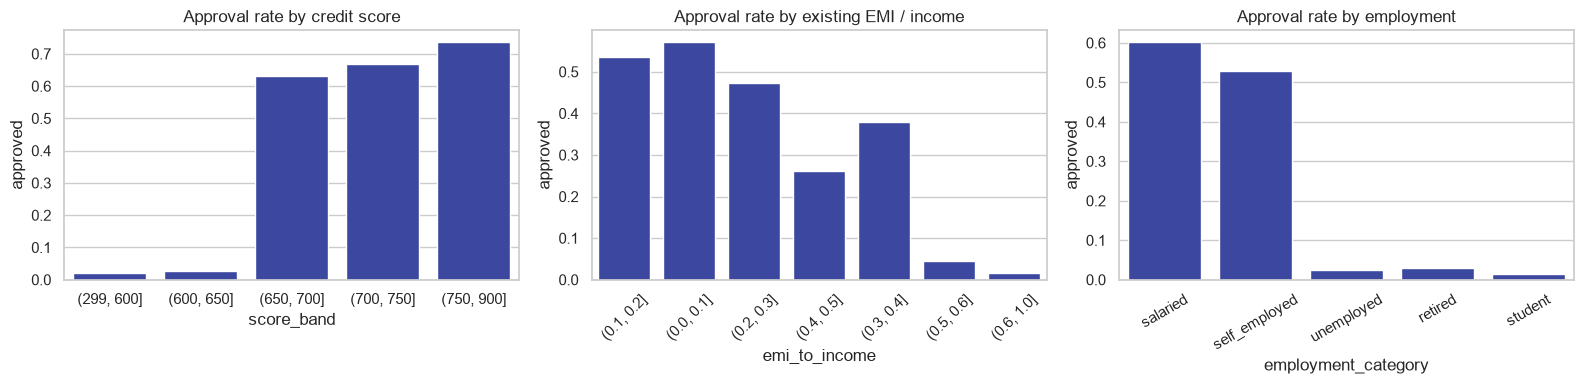

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=df_view, x="score_band", y="approved", ax=axes[0], errorbar=None).set(title="Approval rate by credit score")
bins = pd.cut(df_view.emi_to_income.clip(upper=1), [0, .1, .2, .3, .4, .5, .6, 1])
sns.barplot(x=bins.astype(str), y=df_view.approved, ax=axes[1], errorbar=None).set(title="Approval rate by existing EMI / income")
axes[1].tick_params(axis="x", rotation=45)
cat = df_view.employment_category.str.strip().str.lower().str.replace("-", "_").str.replace(" ", "_")
sns.barplot(x=cat, y=df_view.approved, ax=axes[2], errorbar=None).set(title="Approval rate by employment")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

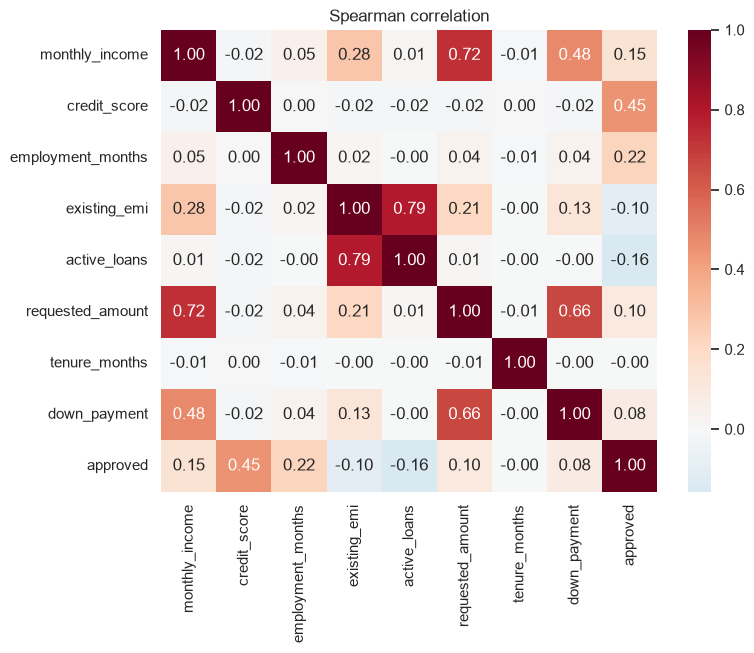

In [10]:
num = ["monthly_income", "credit_score", "employment_months", "existing_emi", "active_loans",
       "requested_amount", "tenure_months", "down_payment", "approved"]
corr = df_view[num].assign(monthly_income=df_view.monthly_income.clip(upper=1_000_000)).corr(method="spearman")
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Spearman correlation"); plt.show()

**Findings.** Approval rises sharply with credit score and falls as existing EMIs take a larger share
of income: the same levers the lender's written policy uses. Only salaried and self-employed applicants are
approved. Region and application date carry no signal and are not used as features (they could also proxy
for protected characteristics).

## 3. Preparation

`app.ml.pipeline.clean` (the same code the training job uses):
* drops duplicate submissions by `application_id`;
* normalises category spellings (unknown -> `other`);
* sets implausible incomes (> 10,00,000 per month) to missing;
* derives ratios a credit analyst would use: `emi_to_income`, `loan_to_annual_income`, `down_payment_ratio`.

Remaining missing values are imputed **inside** the model pipeline (median / most frequent), fitted on the
training folds only, so no information leaks from the test set.

In [11]:
from app.ml.pipeline import clean
from app.ml.features import FEATURES
df = clean(raw)
print(raw.shape, "->", df.shape)
print(df.employment_category.value_counts())
df[FEATURES].isna().sum().to_frame("missing after cleaning").T

(12120, 15) -> (12000, 19)
employment_category
salaried         8082
self_employed    2879
unemployed        400
retired           376
student           263
Name: count, dtype: int64


,monthly_income,credit_score,employment_months,existing_emi,active_loans,requested_amount,tenure_months,down_payment,emi_to_income,loan_to_annual_income,down_payment_ratio,employment_category
missing after cleaning,40,299,381,0,0,0,0,203,40,40,203,0


In [12]:
processed = pd.read_csv(ROOT / "data/processed/loan_applications_clean.csv")
assert len(processed) == len(df), "run `python -m app.ml.train` to refresh data/processed"
print("data/processed/loan_applications_clean.csv matches the cleaning step:", processed.shape)

data/processed/loan_applications_clean.csv matches the cleaning step: (12000, 19)
